In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [24]:
p_cent = 720                                                # image is 1440 wide
k0 = 950                                                    # +-1 measured value
k_cent = np.array([1070, 1072, 1101, 1131, 1310, 849, 800]) # +-1 measured values of k
lamda_cent = np.array([504.7, 492.1, 471.3, 447.1, 388.8, 667.8, 706.5])
                                                            # corresponding wavelength values from manual

In [25]:
# fit model for wavelength depending on dial position k
def lamda_cent_fit (k, bb, aa):
    return bb * k + aa

1219.9236344689577
-0.6629163290991162
1.6536375414480053
0.0015603184245624173


<ErrorbarContainer object of 3 artists>

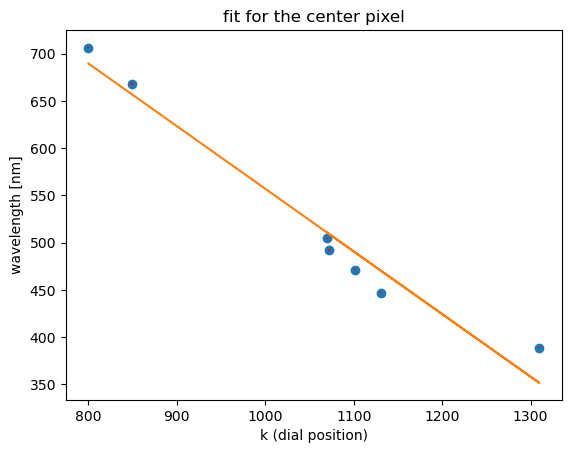

In [26]:
std_k = 1
std_k_cent = np.ones(7) * std_k # uncertenties of k values

from scipy.optimize import curve_fit
# first fit to convert x-error to y-error
popt, pcov = curve_fit(lamda_cent_fit, k_cent, lamda_cent, absolute_sigma=True)

b_prov = popt[0]

# y-error
std_lamda_from_k = np.abs(b_prov * std_k_cent)

# actual fit
popt, pcov = curve_fit(lamda_cent_fit, k_cent, lamda_cent, sigma=std_lamda_from_k, absolute_sigma=True)

# fit parameters a, b for lamda(k) = b*k + a
b = popt[0]
a = popt[1]
print(a)
print(b)

print('========')

std_b = np.sqrt(pcov[0, 0])
std_a = np.sqrt(pcov[1, 1])
print(std_a)
print(std_b)

plt.plot(k_cent, lamda_cent, linestyle='', marker='o')
plt.plot(k_cent, lamda_cent_fit(k_cent, b, a))
plt.xlabel('k (dial position)')
plt.ylabel('wavelength [nm]')
plt.title('fit for the center pixel')
plt.errorbar(k_cent, lamda_cent, std_lamda_from_k, linestyle = '', color='r')

In [27]:
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------

In [28]:
k_fix = 1066                              # +-1 measured value
p_pos = np.array([475, 802, 920])         # pixel position from image +-1
lamda_k = np.array([492.1, 501.5, 504.7]) # values from manual (wavelength)

In [30]:
# fit model including pixel position
def lamda_fit (p, dd, ee):
    return b * k_fix + a + (p - p_cent) / dd + ee

In [31]:
std_p = 1

from scipy.optimize import curve_fit
# first fit to determine y-error from x-error
popt, pcov = curve_fit(lamda_fit, p_pos, lamda_k, absolute_sigma=True)

d_prov = popt[0]
std_lamda_from_p = np.abs(std_p / d_prov)

# actual fit
popt, pcov = curve_fit(lamda_fit, p_pos, lamda_k, sigma=std_lamda_from_p, absolute_sigma=True)
d = popt[0]
e = popt[1]

print(d)
print(e)
std_d = np.sqrt(pcov[0, 0])
print(std_d)
std_e = np.sqrt(pcov[1, 1])
print(std_e)

35.20246389722913
-14.17184858007001
0.10797448295856632
0.016436016454979854


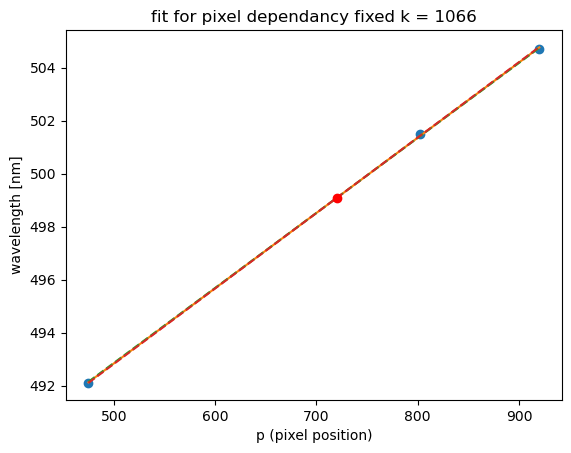

In [ ]:
plt.plot(p_pos, lamda_k, linestyle='', marker='o')
offset = 0
plt.plot(p_pos, lamda_fit(p_pos, d, e) - offset)
plt.plot(p_pos, lamda_fit(p_pos, d + std_d, e) - offset, linestyle='--')
plt.plot(p_pos, lamda_fit(p_pos, d - std_d, e) - offset, linestyle='--')

plt.xlabel('p (pixel position)')
plt.ylabel('wavelength [nm]')
plt.title('fit for pixel dependancy fixed k = 1066')

plt.plot(p_cent, lamda_fit(p_cent, d, e) - offset, marker='o', color='r')
plt.plot(p_cent, lamda_fit(p_cent, d, 0) - offset, marker='o', color='orange')

In [34]:
# final fit function
def lamda (p, k):
    return b * k + a + (p - p_cent) / d

In [35]:
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------

In [36]:
# calculation of the lattice constant

In [37]:
lamda_at_center = 667.8                 # wavelength of middle pixel
beta = 15 * 2 * np.pi / 360             # 15° in radians
k_pos = 850                             # +-1 dial position
k0_fit = (-1) * a / b                   # k0 from the fit
alpha = (k_pos - k0_fit) * 5.8 / 10**5  # calculates the angle alpha based on manual
print(alpha / (2 * np.pi) * 360)        # prints alpha in degrees
print(k0_fit)
print(lamda(p_cent, k0_fit))

-3.290713642388187
1840.2377206891224
0.0


In [38]:
# lattice constant:
d = lamda_at_center / (2 * np.cos(beta) * np.sin(alpha))
print(1 / d)
print(10**5 / d)

-0.00016605655679564544
-16.605655679564542


In [39]:
# error prop:
del_k0_fit_a = (-1) / b
del_k0_fit_b = a / b**2
std_k0_fit = np.sqrt((del_k0_fit_a * std_a)**2 + (del_k0_fit_b * std_b)**2)


del_alpha_k_pos = 5.8 / 10**5
del_alpha_k0_fit = (-1) * 5.8 / 10**5
std_alpha = np.sqrt((del_alpha_k_pos * std_k)**2 + (del_alpha_k0_fit * std_k0_fit)**2)

del_g = 2 * np.cos(beta) * np.cos(alpha) / lamda_at_center
std_g = np.sqrt((del_g * std_alpha)**2)

print(std_g)
print("====")
print(std_k0_fit)
print(std_alpha * 180 / np.pi)

8.538618702853502e-07
====
4.998351249642187
0.016939460651705575


In [40]:
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------
#-------------------------------#-------------------------------#-------------------------------

In [41]:
measurements = np.array([860, 1080, 1112, 1120])    # +-1 k values
balmer_lamda = lamda(p_cent, measurements)          #literature 656.279, 486.135, 434.0472, 410.1734
print(balmer_lamda)
c = 299792458

print('==============')

# error porp:
del_f_a = 1                           # = 1
del_f_b = measurements                # = k
del_f_d = -(p_cent - p_cent) / d**2   # = -(p - p_cent) / d^2
del_f_p = 1 / d                       # = 1 / d
del_f_k = b                           # = b
std_lamda = np.sqrt((del_f_a * std_a)**2
               + (del_f_b * std_b)**2
               + (del_f_d * std_d)**2
               + (del_f_p * std_p)**2
               + (del_f_k * std_k)**2)

print(std_lamda)

[649.81559144 503.97399904 482.76067651 477.45734588]
[2.23038127 2.45228162 2.48685691 2.49558198]


In [42]:
# calculated values for rydborg frequency
nn = np.array([3, 4, 5, 6])                                   # balmer series
balmer_lamda_m = balmer_lamda / 10**9                         # wavelength in m
ryd_freq = c / balmer_lamda_m * 1 / ((1 / 4) - (1 / nn**2))   # formula from manual
print(ryd_freq)
print(np.mean(ryd_freq))
print(np.mean(ryd_freq) / 10**15)
print('---')
print(np.mean(ryd_freq) / c)

print('=============')

# error prop:
del_ryd_lamda = (-1) * c / (balmer_lamda_m)**2 * 1 / ((1 / 4) - (1 / nn**2))
std_ryd = np.sqrt((del_ryd_lamda * std_lamda / 10**9)**2)
print(std_ryd)
print(np.mean(std_ryd) / 10**15)

[3.32172039e+15 3.17257063e+15 2.95712390e+15 2.82552164e+15]
3069234138354055.0
3.069234138354055
---
10237863.083113503
[1.14012391e+13 1.54373771e+13 1.52331048e+13 1.47684834e+13]
0.014210051104589706


In [43]:
# limit of series: f = Rh / 4 | lamda = 4 * c / Rh
print(c / np.mean(ryd_freq) * 4 * 10**9)

print('===========')
# error prop:
del_lamda_lim = (-1) * 4 * c / np.mean(ryd_freq)**2
std_lamda_lim = np.sqrt((del_lamda_lim * np.mean(std_ryd))**2)
print(std_lamda_lim * 10**9)

390.70653392480557
1.8089072269168625


In [44]:
# E_photon = h * c / lamda         (h is planks constant)
# E_photon[eV] = E_photon / e      (e is electornic charge)
e = 1.602176634 * 10**(-19)
h = 6.62607015 * 10**(-34)

print(h * np.mean(ryd_freq) / e)

print('=======')
# error prop:
del_E_photon = h / e
sig_E_photon = np.sqrt((del_E_photon * np.mean(std_ryd))**2)
print(sig_E_photon)

12.693332480286795
0.05876804932488884
